In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   Дата          301355 non-null  str  
 1   Склад         301355 non-null  int64
 2   Контрагент    301355 non-null  str  
 3   Номенклатура  301355 non-null  str  
 4   Количество    301355 non-null  int64
dtypes: int64(2), str(3)
memory usage: 20.0 MB


Сразу переведем столбец "Дата" в правильный формат

In [4]:
df['Дата'] = pd.to_datetime(df['Дата'])

Сгруппируйте данные по дате, посчитайте количество продаж

In [5]:
grouped_df = df.groupby('Дата', as_index=False)['Количество'].sum()

Вывести несколько первых строк сгруппированных данных

In [6]:
print(grouped_df.head())

        Дата  Количество
0 2018-01-04        3734
1 2018-01-05        3643
2 2018-01-06        3193
3 2018-01-07        3298
4 2018-01-09        4055


Нарисуйте график продаж у `grouped_df`

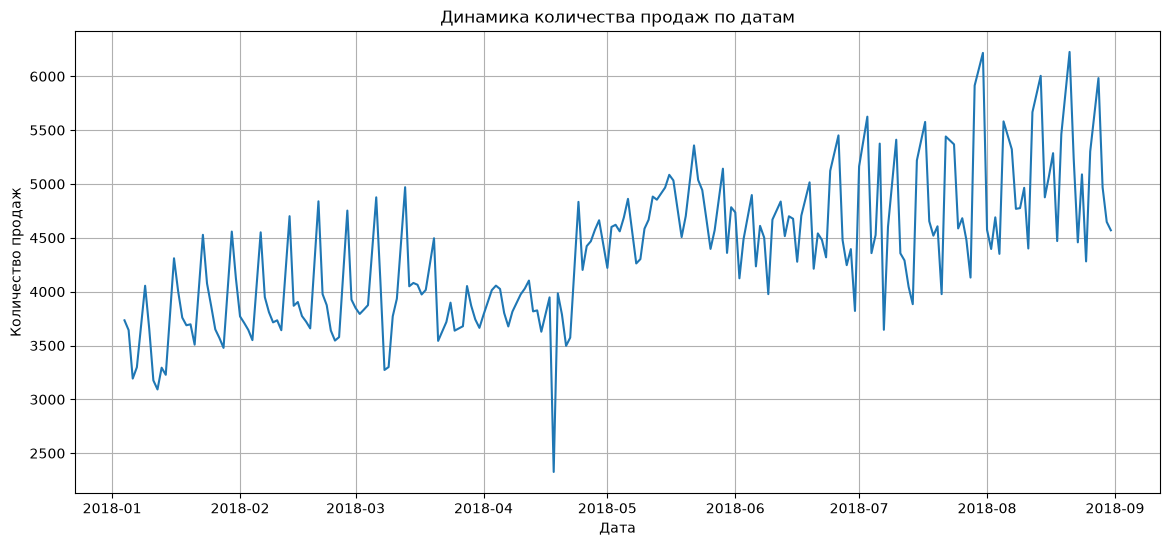

In [7]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=grouped_df, x='Дата', y='Количество')
plt.title('Динамика количества продаж по датам')
plt.xlabel('Дата')
plt.ylabel('Количество продаж')
plt.grid(True)
plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

In [ ]:

##Описание графика «Динамика количества продаж по датам»
##• Общий тренд: На протяжении всего рассматриваемого периода с января по сентябрь 2018 года наблюдается устойчивый восходящий тренд. Если в январе продажи колебались в районе 3100–4300 единиц в день, то к августу–сентябрю диапазон вырос до 4200–6050 единиц.
##• Сезонность и цикличность: На графике отчетливо видны регулярные «пилообразные» колебания с коротким циклом (недельная сезонность). Разница между локальными пиками и спадами внутри каждой недели составляет примерно 700–1200 единиц, что характерно для чередования будних и выходных дней.
##• Аномалии и выбросы: В середине апреля (примерно 17–19 апреля 2018 года, между отметками 2018-04 и 2018-05) зафиксирован резкий аномальный провал, когда дневные продажи одномоментно упали примерно до 2450 единиц (самое низкое значение за весь период), после чего быстро вернулись к привычному уровню.
##• Максимумы и минимумы: Абсолютный максимум продаж приходится на середину августа 2018 года (около 6050 единиц), а локальные подъемы также заметны в начале июня и конце августа. Также в апреле, перед самим провалом, наблюдается небольшое временное снижение общей амплитуды колебаний (продажи держатся в узком коридоре 3600–4100).


Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [8]:
df[df['Количество'] == df['Количество'].max()]

,Дата,Склад,Контрагент,Номенклатура,Количество
218822,2018-06-28,1,address_208,product_0,200


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [10]:
top_product = (
    df[
        (df['Склад'] == 3) &
        (df['Дата'].dt.month.isin([6, 7, 8])) &
        (df['Дата'].dt.dayofweek == 2)
    ]
    .groupby('Номенклатура', as_index=False)['Количество']
    .sum()
    .sort_values(by='Количество', ascending=False)
)

print(top_product.head(1))

  Номенклатура  Количество
1    product_1        2267


In [17]:
!pip install xlrd

Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

Читаем файл: 35188.04.01.2018.01.08.2018.1.0.0.ru.utf8.00000000.xls
Первые 5 строк объединенной таблицы:


,Дата,Количество продаж,T
0,2018-01-04,3734,-14.0750
1,2018-01-05,3643,-16.8625
2,2018-01-06,3193,-13.3000
3,2018-01-07,3298,-12.7500
4,2018-01-09,4055,-6.2500


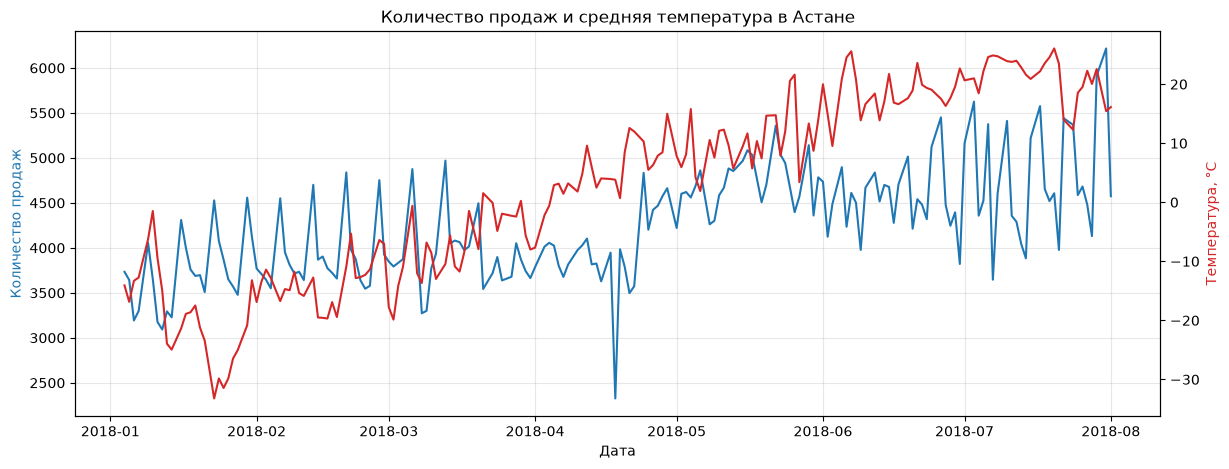

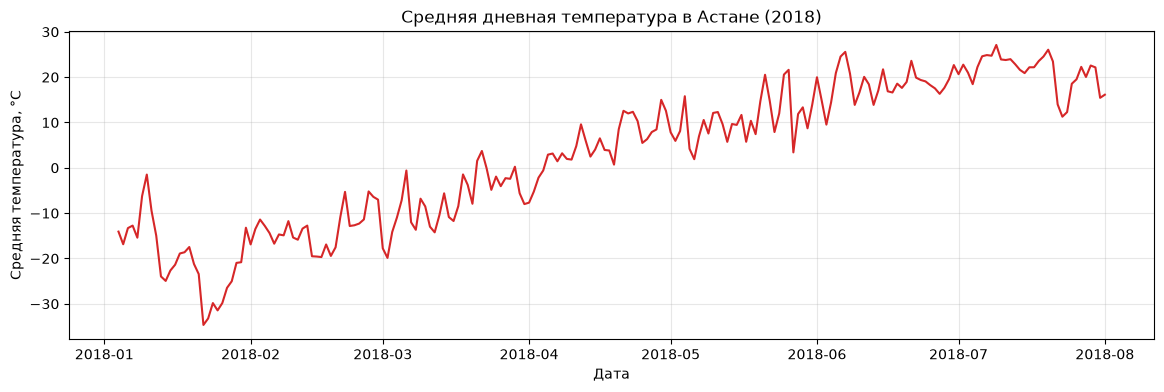

In [20]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

weather_files = glob.glob('*35188*.xls')
file_path = weather_files[0]
print("Читаем файл:", file_path)

weather_raw = pd.read_excel(file_path, skiprows=6, engine='xlrd')

time_col = weather_raw.columns[0]  
weather_raw['Дата'] = pd.to_datetime(weather_raw[time_col], dayfirst=True).dt.floor('D')
weather_raw['T'] = pd.to_numeric(weather_raw['T'], errors='coerce')

daily_weather = weather_raw.groupby('Дата', as_index=False)['T'].mean()

sales_prepared = grouped_df.rename(columns={'Количество': 'Количество продаж'})
merged = pd.merge(sales_prepared, daily_weather, on='Дата', how='inner')

print("Первые 5 строк объединенной таблицы:")
display(merged.head())

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(merged['Дата'], merged['Количество продаж'], color='tab:blue', label='Количество продаж')
ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество продаж', color='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(merged['Дата'], merged['T'], color='tab:red', label='T')
ax2.set_ylabel('Температура, °C', color='tab:red')

plt.title('Количество продаж и средняя температура в Астане')
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(daily_weather['Дата'], daily_weather['T'], color='tab:red')
plt.xlabel('Дата')
plt.ylabel('Средняя температура, °C')
plt.title('Средняя дневная температура в Астане (2018)')
plt.grid(True, alpha=0.3)
plt.show()
